# [Bonus Tasks](svm_segm.ipynb)

In [1]:
import numpy as np
import matplotlib.pyplot as plt

import scipy.ndimage as ndi
import skimage.morphology as morph
import skimage.util
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

In [2]:
def blend_result(img, seg, border_radius=1, interior_opacity=1, interior_opacity_decay=0.9, color=(0,1,0)):
    img  = np.dstack([img] * 3).copy()
    img -= img.min()
    img /= img.max()
    selem  = morph.disk(border_radius)
    seg_bd = np.logical_xor(morph.binary_dilation(seg, selem), morph.binary_erosion(seg, selem))
    mask_decay = ndi.distance_transform_edt(seg)
    for i in range(3):
        opacity = interior_opacity / pow(1 + mask_decay[seg], interior_opacity_decay)
        img[:,:,i][seg] = color[i] * opacity + (1 - opacity) * img[:,:,i][seg]
        img[:,:,i][seg_bd] = color[i]
    return img

each patch is 32 × 32 pixels

In [3]:
patch_sizes = (32, 32)

---

**[Task 1.1.]()** Implement `create_data_matrix`:

takes the 1,024 pixel intensities in each patch and puts them into one row

In [4]:
from skimage.util import view_as_blocks

def create_data_matrix(image):
    patches = view_as_blocks(image, block_shape=(32, 32))
    X = patches.reshape(-1, 32 * 32)
    return X

**[Task 1.2.]()** Implement `create_gt_labels_vector`:

 takes a binary image
as the parameter (the ground truth segmentation), creates the vector of labels 𝑦,
and returns that vector

In [5]:
def create_gt_labels_vector(image):
    patches = create_data_matrix(image)
    y = np.zeros(patches.shape[0], dtype=int)

    for i in range(len(patches)):
        foreground = patches[i].sum()

        if foreground > 512:
            y[i] = 1
        elif foreground == 0:
            y[i] = -1

    return y

If the area of the ground truth image corresponding to an image patch contains
more than 50% foreground, assign the label +1 to that image patch. If that area
contains no foreground, assign the label −1. Otherwise, assign the label 0 

**[Task 1.3.]()** Create the SVM classifier:

In [ ]:
clf = make_pipeline(StandardScaler(), SVC(class_weight='balanced', gamma=0.1))

**[Task 1.3 (a).]()** Create the data matrices for the images `dna-33` and `dna-44`:

eine reihe ist ein patch --> ein column ist eine pixel pos. in dem patch

In [23]:
img_min_33 = plt.imread('data/NIH3T3/im/dna-33.png')
img_min_44 = plt.imread('data/NIH3T3/im/dna-44.png')

dna_33 = create_data_matrix(img_min_33)
dna_44 = create_data_matrix(img_min_44)

**[Task 1.3 (b).]()** Create the corresponding ground truth label vectors:

In [24]:
img33 = plt.imread('data/NIH3T3/gt/33.png')
img44 = plt.imread('data/NIH3T3/gt/44.png')

label_vector_dna33 = create_gt_labels_vector(img33 > 0)
label_vector_dna44 = create_gt_labels_vector(img44 > 0)

**[Task 1.3 (c).]()** Create the *combined* data matrices and ground truth label vectors:

also X gibt uns patch und y den label 

In [25]:

X = np.concatenate((dna_33, dna_44), axis=0)
Y = np.concatenate((label_vector_dna33, label_vector_dna44))
no_zero= Y != 0
X = X[no_zero]
Y = Y[no_zero]


**[Task 1.3 (d).]()** Train the classifier using the data matrix and label vectors from above:

In [30]:
print(Y.dtype)
print(np.unique(Y, return_counts=True))

int64
(array([-1,  1]), array([1564,  545]))


In [31]:
clf.fit(X, Y)

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('svc', SVC(class_weight='balanced', gamma=0.1))])

**[Task 1.4.]()** Implement the function `predict_image`:

In [ ]:
def predict_image(image):
    X = create_data_matrix(image)
    labels = clf.predict(X)

#Arranges that flat list of labels back into a grid matching the patch positions.

    patch_grid = labels.reshape(image.shape[0] // 32,
                                image.shape[1] // 32)

    result = patch_grid == 1
    result = result.repeat(32, axis=0).repeat(32, axis=1)

    return result

Test your implementation:

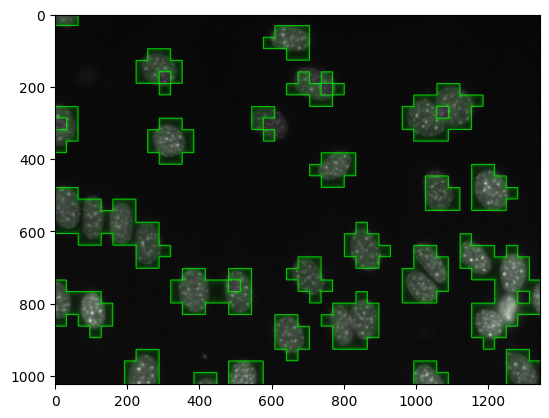

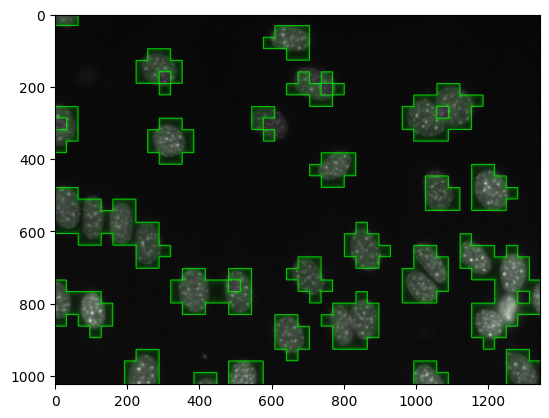

In [35]:
img = plt.imread(f'data/NIH3T3/im/dna-0.png')
seg = predict_image(img)

plt.figure()
plt.imshow(blend_result(img, seg))

**[Task 1.5.]()** Perform batch processing:

dice def:

In [38]:
def compute_dice(bin1, bin2):
    intersection = np.logical_and(bin1, bin2).sum()
    total = bin1.sum() + bin2.sum()

    if total == 0:
        return 1.0

    return 2 * intersection / total

otsu def:

In [41]:
def otsu_thresholding(imgf):
    img8 = (imgf * 255).round().astype(np.uint8)
    scores = np.full(256, np.inf)

    for T in range(1, 256):
        class1 = img8[img8 < T]
        class2 = img8[img8 >= T]

        if class1.size > 0 and class2.size > 0:
            scores[T] = (
                class1.size * class1.var()
                + class2.size * class2.var()
            )

    T_star = np.argmin(scores)
    seg = img8 >= T_star
    return seg

In [43]:
svm_scores = []
otsu_scores = []

for i in [28, 29, 33, 44, 46, 49]:
    image = plt.imread(f'data/NIH3T3/im/dna-{i}.png')
    gt = plt.imread(f'data/NIH3T3/gt/{i}.png') > 0

    svm_result = predict_image(image)
    svm_dice = compute_dice(svm_result, gt)
    svm_scores.append(svm_dice)

    otsu_result = otsu_thresholding(image)
    otsu_dice = compute_dice(otsu_result, gt)
    otsu_scores.append(otsu_dice)

    print(f'Image {i}: SVM = {svm_dice:.3f}, Otsu = {otsu_dice:.3f}')

print(f'mittel SVM Dice:  {np.mean(svm_scores):.3f}')
print(f'mittel Otsu Dice: {np.mean(otsu_scores):.3f}')

Image 28: SVM = 0.721, Otsu = 0.753
Image 29: SVM = 0.660, Otsu = 0.648
Image 33: SVM = 0.678, Otsu = 0.430
Image 44: SVM = 0.713, Otsu = 0.579
Image 46: SVM = 0.617, Otsu = 0.076
Image 49: SVM = 0.689, Otsu = 0.797
mittel SVM Dice:  0.680
mittel Otsu Dice: 0.547


verbesserung dice: (mit chatgpt)

smoothing of image before svm

In [44]:
from scipy.ndimage import gaussian_filter
from sklearn.base import clone

# Smooth only the original images
smooth33 = gaussian_filter(img_min_33, sigma=1)
smooth44 = gaussian_filter(img_min_44, sigma=1)

X_smooth = np.concatenate((
    create_data_matrix(smooth33),
    create_data_matrix(smooth44)
))

# Keep the original ground-truth labels
Y_smooth = np.concatenate((label_vector_dna33, label_vector_dna44))

no_zero = Y_smooth != 0
X_smooth = X_smooth[no_zero]
Y_smooth = Y_smooth[no_zero]

# Create a fresh classifier with the same settings
clf_smooth = clone(clf)
clf_smooth.fit(X_smooth, Y_smooth)

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('svc', SVC(class_weight='balanced', gamma=0.1))])

In [45]:
def predict_image_smooth(image):
    smoothed = gaussian_filter(image, sigma=1)
    X = create_data_matrix(smoothed)
    labels = clf_smooth.predict(X)

    patch_grid = labels.reshape(image.shape[0] // 32,
                                image.shape[1] // 32)

    result = patch_grid == 1
    return result.repeat(32, axis=0).repeat(32, axis=1)

In [46]:
before_scores = []
after_scores = []

for i in [28, 29, 33, 44, 46, 49]:
    image = plt.imread(f'data/NIH3T3/im/dna-{i}.png')
    gt = plt.imread(f'data/NIH3T3/gt/{i}.png') > 0

    before = compute_dice(predict_image(image), gt)
    after = compute_dice(predict_image_smooth(image), gt)

    before_scores.append(before)
    after_scores.append(after)

    print(f'Image {i}: before = {before:.3f}, after = {after:.3f}')

print(f'\nMean before: {np.mean(before_scores):.3f}')
print(f'Mean after:  {np.mean(after_scores):.3f}')

Image 28: before = 0.721, after = 0.716
Image 29: before = 0.660, after = 0.661
Image 33: before = 0.678, after = 0.672
Image 44: before = 0.713, after = 0.713
Image 46: before = 0.617, after = 0.613
Image 49: before = 0.689, after = 0.687

Mean before: 0.680
Mean after:  0.677
